# Superstore Sales: Profitability & Sales-Velocity Analysis

**Goal:** Clean the Superstore dataset, aggregate Sales and Profit by Category, Region and Segment, visualise monthly sales velocity and the discount-vs-profit relationship, and document business findings.

**Steps:** 1) Load → 2) Clean (nulls, dates, Year-Month) → 3) Aggregate → 4) Visualise → 5) Business findings

## 1. Load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.2f}".format

FILE = "superstore_sales.csv"   # update path if needed
raw = pd.read_csv(FILE)
print("Raw shape:", raw.shape)
raw.tail(3)

Raw shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10797,Yes,US-2018-151127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10798,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10799,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data cleaning

The raw file has a structural issue worth handling explicitly: **after the 9,994 real order lines, two small lookup tables are appended to the same sheet** (a *People* table of regional managers and a *Returns* table where the `Row ID` column holds "Yes"). These rows are empty in every sales column, so they show up as ~806 "null rows". They are not missing data; they are different tables, so I separate them rather than drop them blindly.

In [2]:
# 2a. Split the appended lookup tables from the real order lines
orders_mask = raw["Order Date"].notna()
orders  = raw[orders_mask].copy()
extras  = raw[~orders_mask].copy()

# People table: manager name sits in "Row ID", region in "Order ID"
ppl = extras[~extras["Row ID"].isin(["Yes", "Person", "Returned"]) & extras["Order ID"].isin(["West","East","Central","South"])]
people  = ppl.rename(columns={"Row ID": "Person", "Order ID": "Region"})[["Person", "Region"]].reset_index(drop=True)
# Returns table: "Yes" in "Row ID", returned Order ID next to it
returns = (extras[extras["Row ID"].eq("Yes")][["Order ID"]]
           .drop_duplicates().reset_index(drop=True))

print(f"Order lines: {len(orders):,} | appended rows separated: {len(extras):,}")
print(f"Regional managers: {len(people)} | distinct returned orders: {len(returns):,}")

Order lines: 9,994 | appended rows separated: 806
Regional managers: 4 | distinct returned orders: 296


In [3]:
# 2b. Types and dates
orders["Row ID"] = orders["Row ID"].astype(int)
orders["Order Date"] = pd.to_datetime(orders["Order Date"], format="%m/%d/%Y", errors="raise")
orders["Ship Date"]  = pd.to_datetime(orders["Ship Date"],  format="%m/%d/%Y", errors="raise")
orders["Quantity"]   = orders["Quantity"].astype(int)

# Year-Month features
orders["Year"]       = orders["Order Date"].dt.year
orders["Month"]      = orders["Order Date"].dt.month
orders["Year-Month"] = orders["Order Date"].dt.to_period("M")

# Sanity checks
assert (orders["Ship Date"] >= orders["Order Date"]).all(), "Ship date before order date"
assert orders["Row ID"].is_unique
print("Date range:", orders["Order Date"].min().date(), "->", orders["Order Date"].max().date())

Date range: 2015-01-03 -> 2018-12-30


In [4]:
# 2c. Remaining nulls and duplicates
nulls = orders.isna().sum()
print("Nulls remaining:\n", nulls[nulls > 0], "\n")

# Postal Code: only Burlington, VT is missing it (a known gap in this dataset), so fill it
print(orders.loc[orders["Postal Code"].isna(), ["City", "State"]].drop_duplicates())
orders.loc[(orders["City"] == "Burlington") & (orders["State"] == "Vermont"), "Postal Code"] = 5401
orders["Postal Code"] = orders["Postal Code"].astype(int).astype(str).str.zfill(5)

# Duplicates (ignoring the surrogate Row ID)
dupes = orders.duplicated(subset=orders.columns.difference(["Row ID"]), keep="first")
print(f"\nExact duplicate order lines: {dupes.sum()} -> removed")
df = orders[~dupes].reset_index(drop=True)

# Derived metrics
df["Profit Margin"] = df["Profit"] / df["Sales"]
df["Returned"] = df["Order ID"].isin(returns["Order ID"])
print("Clean shape:", df.shape)
df.head()

Nulls remaining:
 Postal Code    11
dtype: int64 

            City    State
2234  Burlington  Vermont

Exact duplicate order lines: 1 -> removed
Clean shape: (9993, 26)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Year-Month,Profit Margin,Returned
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91,2017,11,2017-11,0.16,False
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58,2017,11,2017-11,0.30,False
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87,2017,6,2017-06,0.47,False
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03,2016,10,2016-10,-0.40,False
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52,2016,10,2016-10,0.11,False


## 3. Aggregate Sales & Profit by Category, Region and Segment

In [5]:
def summarise(keys):
    g = (df.groupby(keys)
           .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                Orders=("Order ID", "nunique"), Avg_Discount=("Discount", "mean"))
           .assign(Margin=lambda x: x["Profit"] / x["Sales"],
                   Sales_Share=lambda x: x["Sales"] / x["Sales"].sum()))
    return g.sort_values("Profit", ascending=False)

by_cat = summarise("Category");  by_reg = summarise("Region");  by_seg = summarise("Segment")
display(by_cat); display(by_reg); display(by_seg)

,Sales,Profit,Orders,Avg_Discount,Margin,Sales_Share
Category,,,,,,
Technology,"836,154.03","145,454.95",1544,0.13,0.17,0.36
Office Supplies,"719,047.03","122,490.80",3742,0.16,0.17,0.31
Furniture,"741,718.42","18,463.33",1764,0.17,0.02,0.32


,Sales,Profit,Orders,Avg_Discount,Margin,Sales_Share
Region,,,,,,
West,"725,457.82","108,418.45",1611,0.11,0.15,0.32
East,"678,499.87","91,534.84",1401,0.15,0.13,0.30
South,"391,721.91","46,749.43",822,0.15,0.12,0.17
Central,"501,239.89","39,706.36",1175,0.24,0.08,0.22


,Sales,Profit,Orders,Avg_Discount,Margin,Sales_Share
Segment,,,,,,
Consumer,"1,161,401.34","134,119.21",2586,0.16,0.12,0.51
Corporate,"706,146.37","91,979.13",1514,0.16,0.13,0.31
Home Office,"429,371.78","60,310.74",909,0.15,0.14,0.19


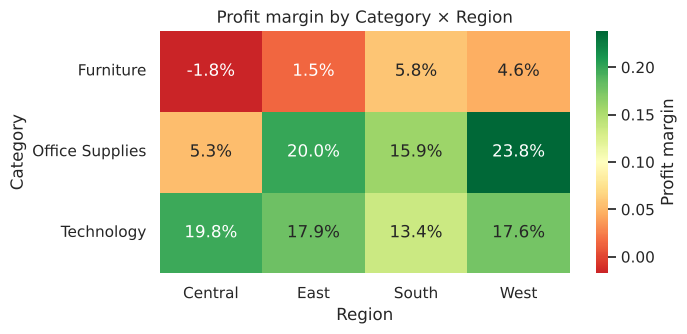

In [6]:
cat_reg = summarise(["Category", "Region"])
heat = cat_reg["Margin"].unstack()
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.heatmap(heat, annot=True, fmt=".1%", cmap="RdYlGn", center=0.10, cbar_kws={"label": "Profit margin"}, ax=ax)
ax.set_title("Profit margin by Category × Region"); plt.tight_layout(); plt.show()

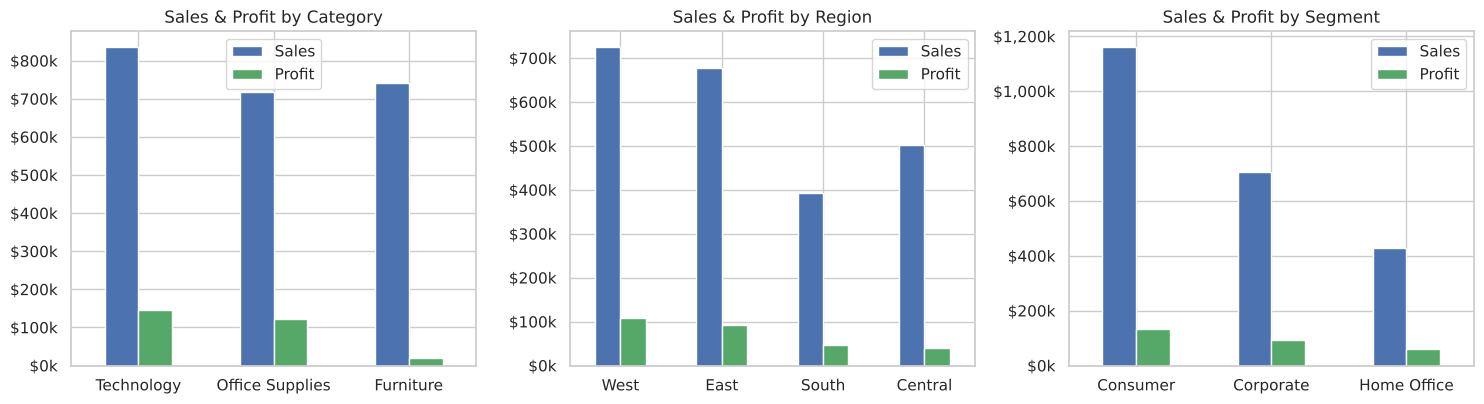

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, t) in zip(axes, [("Category", by_cat), ("Region", by_reg), ("Segment", by_seg)]):
    t[["Sales", "Profit"]].plot.bar(ax=ax, color=["#4C72B0", "#55A868"], rot=0)
    ax.set_title(f"Sales & Profit by {name}"); ax.set_xlabel("")
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1e3:,.0f}k"))
plt.tight_layout(); plt.show()

## 4. Monthly sales velocity

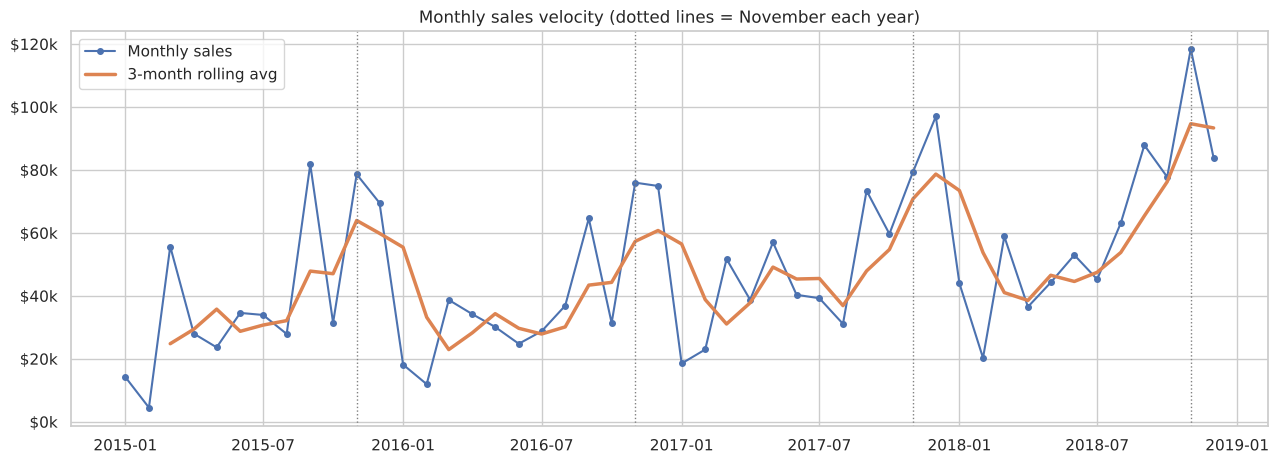

In [8]:
monthly = (df.groupby("Year-Month")
             .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum")))
monthly.index = monthly.index.to_timestamp()
monthly["Rolling_3M"] = monthly["Sales"].rolling(3).mean()
monthly["MoM_%"] = monthly["Sales"].pct_change() * 100

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(monthly.index, monthly["Sales"], marker="o", ms=4, lw=1.5, label="Monthly sales", color="#4C72B0")
ax.plot(monthly.index, monthly["Rolling_3M"], lw=2.5, label="3-month rolling avg", color="#DD8452")
for y in range(2015, 2019):
    ax.axvline(pd.Timestamp(f"{y}-11-01"), color="grey", ls=":", lw=1)
ax.set_title("Monthly sales velocity (dotted lines = November each year)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1e3:,.0f}k")); ax.legend()
plt.tight_layout(); plt.show()

,Sales,Profit,Sales_YoY,Margin
Year,,,,
2015,"483,966.13","49,556.03",NaN,0.10
2016,"470,532.51","61,618.60",-0.03,0.13
2017,"609,205.60","81,795.17",0.29,0.13
2018,"733,215.26","93,439.27",0.20,0.13


Sep + Nov + Dec share of total sales: 42.9%
Jan + Feb share of total sales:       6.7%


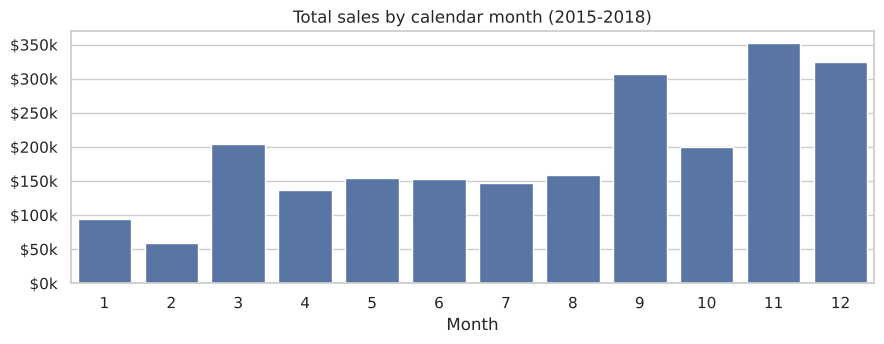

In [9]:
yearly = df.groupby("Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
yearly["Sales_YoY"] = yearly["Sales"].pct_change()
yearly["Margin"] = yearly["Profit"] / yearly["Sales"]
display(yearly)

season = df.groupby("Month")["Sales"].sum()
print(f"Sep + Nov + Dec share of total sales: {season.loc[[9, 11, 12]].sum() / season.sum():.1%}")
print(f"Jan + Feb share of total sales:       {season.loc[[1, 2]].sum() / season.sum():.1%}")
fig, ax = plt.subplots(figsize=(9, 3.6))
sns.barplot(x=season.index, y=season.values, color="#4C72B0", ax=ax)
ax.set_title("Total sales by calendar month (2015-2018)"); ax.set_xlabel("Month")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1e3:,.0f}k")); plt.tight_layout(); plt.show()

## 5. Discount vs profit

,Lines,Sales,Profit,Margin
Discount,,,,
0%,4798,"1,087,908.47","320,987.60",0.30
0-10%,94,"54,369.35","9,029.18",0.17
10-20%,3709,"792,152.89","91,756.30",0.12
20-30%,226,"102,945.28","-10,357.22",-0.10
30-50%,310,"195,314.76","-48,447.73",-0.25
>50%,856,"64,228.74","-76,559.05",-1.19


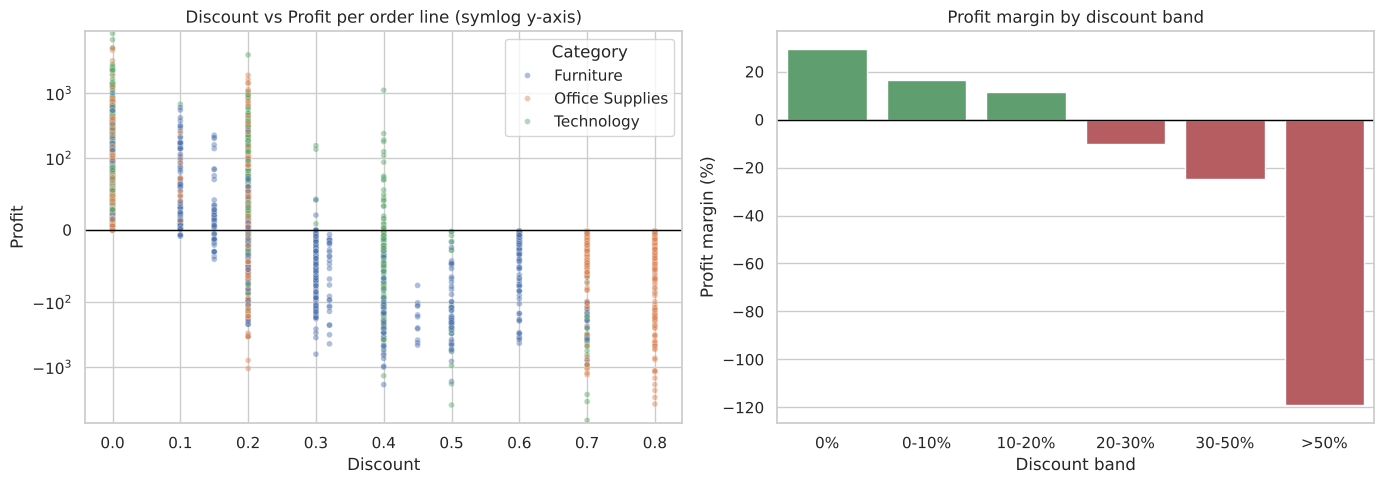

Correlation (Discount, Profit): -0.219


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Line-level scatter, symlog y-axis so extreme outliers don't flatten the picture
sns.scatterplot(data=df, x="Discount", y="Profit", hue="Category", alpha=0.45, s=18, ax=axes[0])
axes[0].set_yscale("symlog", linthresh=100); axes[0].axhline(0, color="black", lw=1)
axes[0].set_title("Discount vs Profit per order line (symlog y-axis)")

# (b) Margin by discount band
bands = pd.cut(df["Discount"], [-0.001, 0, 0.1, 0.2, 0.3, 0.5, 1.0],
               labels=["0%", "0-10%", "10-20%", "20-30%", "30-50%", ">50%"])
band = (df.groupby(bands, observed=True)
          .agg(Lines=("Sales", "size"), Sales=("Sales", "sum"), Profit=("Profit", "sum"))
          .assign(Margin=lambda x: x["Profit"] / x["Sales"]))
display(band)
sns.barplot(x=band.index.astype(str), y=band["Margin"] * 100, hue=band.index.astype(str), legend=False,
            palette=["#55A868" if m > 0 else "#C44E52" for m in band["Margin"]], ax=axes[1])
axes[1].axhline(0, color="black", lw=1); axes[1].set_ylabel("Profit margin (%)"); axes[1].set_xlabel("Discount band")
axes[1].set_title("Profit margin by discount band")
plt.tight_layout(); plt.show()

print("Correlation (Discount, Profit):", round(df["Discount"].corr(df["Profit"]), 3))

In [11]:
# Where does the discounting happen, and what does it cost?
sub = (df.groupby("Sub-Category")
         .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Avg_Discount=("Discount", "mean"))
         .assign(Margin=lambda x: x["Profit"] / x["Sales"]).sort_values("Profit"))
display(sub.head(5))

deep = df[df["Discount"] > 0.20]
print(f"Lines discounted >20%: {len(deep):,} ({len(deep)/len(df):.1%} of lines), "
      f"Sales ${deep['Sales'].sum():,.0f}, Profit ${deep['Profit'].sum():,.0f}")
print(f"Profit on lines discounted <=20%: ${df.loc[df['Discount'] <= 0.20, 'Profit'].sum():,.0f}")

,Sales,Profit,Avg_Discount,Margin
Sub-Category,,,,
Tables,"206,965.53","-17,725.48",0.26,-0.09
Bookcases,"114,880.00","-3,472.56",0.21,-0.03
Supplies,"46,673.54","-1,189.10",0.08,-0.03
Fasteners,"3,024.28",949.52,0.08,0.31
Machines,"189,238.63","3,384.76",0.31,0.02


Lines discounted >20%: 1,392 (13.9% of lines), Sales $362,489, Profit $-135,364
Profit on lines discounted <=20%: $421,773


## 6. Business findings

Each finding is tied to the numbers computed above (after cleaning: 9,993 order lines, 2015-2018, about $2.30M sales and $286k profit).

### Finding 1: Growth is strong but heavily seasonal
- Sales fell about 3% in 2016, then grew **+29% in 2017 and +20% in 2018** (to roughly $733k), while margin held around 13%.
- **September, November and December generate about 43% of all sales**; January and February together contribute under 7%. The 3-month rolling average makes the same peak-and-trough rhythm visible every year.
- **So what:** inventory, staffing and logistics need to be sized for a Q4-weighted year, and Jan-Feb is the obvious window for promotions that smooth demand.

### Finding 2: Discounts above 20% are where profit disappears
- Lines with **no discount earn about a 30% margin**; 10-20% discounts earn about 12%.
- Beyond 20% every band loses money: 20-30% runs at about -10%, 30-50% at about -25%, and **>50% at about -119%** (every $1 sold costs roughly $1.19 more than it earns).
- Only **13.9% of lines are discounted >20%, yet they lose about $135k**, while all lines at or below 20% earn about $422k. The Discount-Profit correlation is -0.22.
- **So what:** a hard approval threshold at 20% would remove a large loss pool at low revenue risk (these lines are only about 16% of sales).

### Finding 3: Furniture is a large category that barely earns money
- Furniture is about **32% of sales but only about 2.5% margin**, and roughly 6% of total profit ($18k of $286k). Technology and Office Supplies each run about 17% margin and together deliver about 94% of profit.
- Within Furniture, **Tables lose about $17.7k (-8.6% margin)** and Bookcases lose about $3.5k; these also carry some of the heaviest average discounts (Tables about 26%, Bookcases about 21%).
- **So what:** Furniture growth is not translating into profit. Reprice or renegotiate supplier cost on Tables and Bookcases before pushing more volume.

### Finding 4: Central region has a discount problem, not a demand problem
- Central is about 22% of sales but only about 14% of profit, with the **lowest margin (about 7.9% vs 14.9% in West)**.
- It also has the **highest average discount (about 24% vs about 11% in West)**, and **Central Furniture is the only Category x Region cell with negative margin** (about -1.8%, see heatmap).
- **So what:** the gap tracks discount behaviour, so a Central-specific discount policy is the first lever to pull. This is correlation, not proof of cause; mix differences also play a part.

### Finding 5: Consumer is the biggest segment but the least profitable per dollar
- Consumer brings about **51% of sales at about 11.5% margin**; Corporate earns about 13.0% and **Home Office about 14.0%** (19% of sales).
- Average discount is nearly identical across segments (about 15-16%), so the gap is more likely driven by product mix and pricing than by segment-specific discounting. That would need a segment x sub-category drill-down to confirm.
- **So what:** Home Office and Corporate are the more efficient places to spend acquisition budget, and Consumer margins improve most from the fixes in Findings 2 and 3.

## 7. Recommended next steps
- Cap discounts at ~20% by default and require approval above it, starting with Furniture and Central.
- Reprice or renegotiate Tables, Bookcases and Supplies, or pull the deepest-discount SKUs.
- Front-load inventory and fulfilment capacity for Sep-Dec; test promotions in Jan-Feb to smooth demand.
- Shift marketing toward Home Office / Corporate and high-margin sub-categories (Copiers, Paper, Accessories).